# Model Churn 180 Hari — PT Graha Material Nusantara

Notebook ini membangun **model prediksi churn** untuk pelanggan B2B distributor material bangunan.
Keluaran utamanya adalah tabel skor risiko per pelanggan, tabel evaluasi model, pemicu churn,
dan risiko per segmen — semuanya diekspor ke `data/processed/churn/` untuk dipakai tim dashboard.

**Definisi yang dipakai konsisten:**

- Aktivitas pelanggan = transaksi berstatus `Selesai` atau `Retur`. Pesanan `Dibatalkan` tidak dihitung.
- **Churn (deskriptif, untuk KPI):** tidak ada aktivitas selama 180 hari terakhir.
- **Churn (label ML):** pada akhir bulan *m*, pelanggan masih aktif (ada aktivitas dalam 180 hari
  terakhir) dan tidak ada aktivitas pada 180 hari **berikutnya**.
- Label hanya bisa dihitung sampai **April 2026**, karena jendela 180 hari setelahnya harus berada
  di dalam periode data (berakhir 31 Oktober 2026).

**Mengapa panel, bukan satu snapshot?** Snapshot tunggal hanya menghasilkan 100 baris dengan 30
kejadian churn — terlalu sedikit untuk ML. Panel pelanggan-bulan memberi ribuan contoh dengan
label yang sama, dan validasi tetap dikelompokkan per pelanggan agar tidak bocor.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

AKAR_NOTEBOOK = Path.cwd().resolve()
if not (AKAR_NOTEBOOK / "src").exists():
    AKAR_NOTEBOOK = AKAR_NOTEBOOK.parent
sys.path.insert(0, str(AKAR_NOTEBOOK))

from src.graha import (
    AKHIR_DATA,
    CHURN_DIR,
    GAMBAR_DIR,
    PALET,
    aktivitas,
    atur_gaya,
    muat_dimensi,
    muat_transaksi,
    rupiah,
    siapkan_folder,
    simpan,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
atur_gaya()
siapkan_folder()
SEED = 42

## 0. Fondasi data: koreksi harga dan kolom turunan

Data bersih dari notebook cleaning masih memuat **bug pemisah ribuan**: nilai seperti
`Rp 231.100` dibaca sebagai `231,1`. Saya tidak mengubah notebook cleaning (milik bagian lain),
tetapi mengoreksi di sini dan menyimpan satu tabel analitik bersama supaya notebook forecasting
dan tim dashboard memakai angka yang sama.

Aturan koreksi: harga yang kurang dari 1% harga acuan produk dikali 1.000. Rasio setelah koreksi
harus kembali wajar (sekitar 0,85–1,55 karena kenaikan harga 2019–2026).

In [2]:
transaksi = muat_transaksi()
dimensi = muat_dimensi()

dikoreksi = transaksi["harga_satuan"] != transaksi["harga_satuan_bersih"]
selesai = transaksi["status_pesanan"] == "Selesai"
omzet_sebelum = (
    transaksi.loc[selesai, "jumlah"]
    * transaksi.loc[selesai, "harga_satuan"]
    * (1 - transaksi.loc[selesai, "diskon_persen"] / 100)
).sum()
omzet_sesudah = transaksi.loc[selesai, "omzet"].sum()

ringkas_harga = pd.DataFrame(
    {
        "metrik": [
            "baris harga dikoreksi",
            "persen baris",
            "omzet sebelum koreksi",
            "omzet setelah koreksi",
            "selisih omzet",
        ],
        "nilai": [
            f"{dikoreksi.sum():,}",
            f"{dikoreksi.mean() * 100:.2f}%",
            rupiah(omzet_sebelum),
            rupiah(omzet_sesudah),
            rupiah(omzet_sesudah - omzet_sebelum),
        ],
    }
)
ringkas_harga

,metrik,nilai
0,baris harga dikoreksi,970
1,persen baris,6.47%
2,omzet sebelum koreksi,Rp 35.96 M
3,omzet setelah koreksi,Rp 38.41 M
4,selisih omzet,Rp 2.45 M


In [3]:
rasio = (
    transaksi.loc[selesai, "harga_satuan_bersih"] / transaksi.loc[selesai, "harga_jual_acuan"]
)
print("rasio harga setelah koreksi:")
print(rasio.describe(percentiles=[0.01, 0.5, 0.99]).round(3).to_string())

kolom_simpan = [
    "id_transaksi", "nomor_pesanan", "tanggal_transaksi", "id_pelanggan", "id_produk",
    "id_sales", "jumlah", "harga_satuan", "harga_satuan_bersih", "harga_modal_bersih",
    "diskon_persen", "ongkos_kirim", "metode_pembayaran", "termin_pembayaran",
    "status_pesanan", "tanggal_kirim", "status_pembayaran", "jenis_pelanggan", "segmen",
    "id_wilayah", "provinsi", "kota", "region", "sla_kirim_hari", "id_kategori",
    "omzet", "lead_time_hari", "terlambat_hari", "is_retur", "is_batal",
    "is_terlambat", "is_terlambat_parah", "is_belum_lunas", "periode", "tahun",
]
simpan(transaksi[kolom_simpan].assign(periode=lambda d: d["periode"].astype(str)),
       Path(AKAR_NOTEBOOK) / "data" / "processed" / "transaksi_analitik.csv")

rasio harga setelah koreksi:
count   14,140.00
mean         1.20
std          0.14
min          0.96
1%           0.99
50%          1.20
99%          1.48
max          1.55
  tersimpan: data\processed\transaksi_analitik.csv (15,000 baris)


## 1. KPI churn deskriptif per 31 Oktober 2026

Pelanggan dinilai hanya jika sudah terdaftar minimal 90 hari dan punya minimal dua pesanan,
sesuai definisi di metadata dataset. Hasilnya dipakai untuk Halaman 1 dashboard.

In [4]:
akt = aktivitas(transaksi)
snapshot = AKHIR_DATA

pelanggan = dimensi["pelanggan"].copy()
wilayah = dimensi["wilayah"]
pelanggan = pelanggan.merge(
    wilayah[["id_wilayah", "provinsi", "kota", "region"]], on="id_wilayah", how="left"
)

ringkas_pelanggan = akt.groupby("id_pelanggan").agg(
    terakhir=("tanggal_transaksi", "max"),
    jumlah_pesanan=("nomor_pesanan", "nunique"),
    omzet_total=("omzet", "sum"),
)
pelanggan = pelanggan.merge(ringkas_pelanggan, on="id_pelanggan", how="left")
pelanggan["recency_hari"] = (snapshot - pelanggan["terakhir"]).dt.days
pelanggan["tenure_hari"] = (snapshot - pelanggan["tanggal_registrasi"]).dt.days
pelanggan["aktif"] = pelanggan["recency_hari"] <= 180
pelanggan["dinilai"] = (pelanggan["tenure_hari"] >= 90) & (pelanggan["jumlah_pesanan"] >= 2)
pelanggan["churn"] = pelanggan["dinilai"] & ~pelanggan["aktif"]

dinilai = pelanggan[pelanggan["dinilai"]]
kpi = pd.DataFrame(
    {
        "tanggal_snapshot": [snapshot.date()],
        "total_pelanggan": [len(pelanggan)],
        "pelanggan_dinilai": [len(dinilai)],
        "pelanggan_aktif": [int(dinilai["aktif"].sum())],
        "pelanggan_churn": [int(dinilai["churn"].sum())],
        "churn_rate": [dinilai["churn"].mean()],
        "omzet_12_bulan": [
            akt.loc[akt["tanggal_transaksi"] > snapshot - pd.Timedelta(days=365), "omzet"].sum()
        ],
    }
)
print(kpi.T.to_string(header=False))
simpan(kpi, CHURN_DIR / "churn_snapshot_kpi.csv")

tanggal_snapshot        2026-10-31
total_pelanggan                100
pelanggan_dinilai              100
pelanggan_aktif                 70
pelanggan_churn                 30
churn_rate                    0.30
omzet_12_bulan    5,133,411,908.45
  tersimpan: data\processed\churn\churn_snapshot_kpi.csv (1 baris)


## 2. Tren churn bulanan

Untuk setiap akhir bulan dihitung proporsi pelanggan yang dinilai tetapi sudah tidak aktif
180 hari. Ini **prevalensi churn**, bukan jumlah kejadian baru, sehingga garisnya bergerak
lambat. Berguna untuk melihat sejak kapan churn memburuk.

  tersimpan: data\processed\churn\churn_rate_monthly.csv (82 baris)


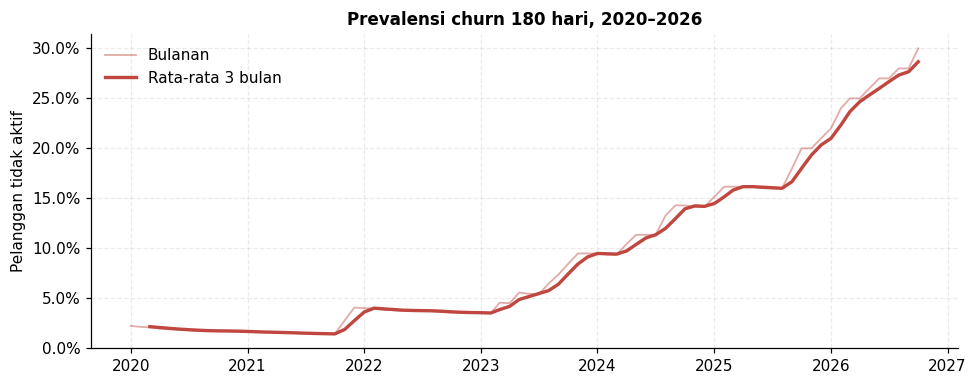

In [5]:
baris_tren = []
for periode in pd.period_range("2020-01", "2026-10", freq="M"):
    akhir = periode.to_timestamp("M")
    dinilai_bulan = pelanggan[
        (pelanggan["tanggal_registrasi"] <= akhir - pd.Timedelta(days=90))
        & (pelanggan["terakhir"].notna())
        & (pelanggan["jumlah_pesanan"] >= 2)
    ].copy()
    dinilai_bulan["aktif_bulan"] = dinilai_bulan["terakhir"] > akhir - pd.Timedelta(days=180)
    baris_tren.append(
        {
            "periode": periode,
            "n_dinilai": len(dinilai_bulan),
            "n_churn": int((~dinilai_bulan["aktif_bulan"]).sum()),
            "churn_rate": (~dinilai_bulan["aktif_bulan"]).mean() if len(dinilai_bulan) else np.nan,
        }
    )

tren_churn = pd.DataFrame(baris_tren)
tren_churn["periode_str"] = tren_churn["periode"].astype(str)
simpan(tren_churn[["periode_str", "n_dinilai", "n_churn", "churn_rate"]].rename(columns={"periode_str": "periode"}),
       CHURN_DIR / "churn_rate_monthly.csv")

fig, ax = plt.subplots(figsize=(9, 3.6))
x = tren_churn["periode"].dt.to_timestamp()
ax.plot(x, tren_churn["churn_rate"], color=PALET["merah"], linewidth=1.2, alpha=0.45, label="Bulanan")
ax.plot(x, tren_churn["churn_rate"].rolling(3).mean(), color=PALET["merah"], linewidth=2.2, label="Rata-rata 3 bulan")
ax.set_title("Prevalensi churn 180 hari, 2020–2026")
ax.set_ylabel("Pelanggan tidak aktif")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_rate_bulanan.png")
plt.show()

## 3. Panel pelanggan-bulan dan label churn

Satu baris = satu pelanggan pada akhir satu bulan. Syarat masuk panel:
terdaftar ≥90 hari, ≥2 pesanan sampai bulan tersebut, dan masih aktif dalam 180 hari terakhir.
Fitur hanya memakai data **sampai akhir bulan itu**; label memakai 180 hari **setelahnya**.

In [6]:
BULAN_PIVOT = pd.period_range("2019-01", "2026-10", freq="M")
BULAN_PANEL = pd.period_range("2020-01", "2026-04", freq="M")


def susun_fitur_historis(data_aktif: pd.DataFrame, bulan_list) -> pd.DataFrame:
    """Fitur per pelanggan-bulan: recency, jarak pesanan, keragaman produk, label churn."""
    hasil = []
    for pid, g in data_aktif.groupby("id_pelanggan", sort=True):
        g = g.sort_values("tanggal_transaksi")
        tanggal = g["tanggal_transaksi"].to_numpy()
        pesanan = g.groupby("nomor_pesanan")["tanggal_transaksi"].min().sort_values()
        tanggal_pesanan = pesanan.to_numpy()
        registrasi = g["tanggal_registrasi"].iloc[0]

        for periode in bulan_list:
            akhir = periode.to_timestamp("M")
            batas = akhir.to_datetime64()
            i = int(np.searchsorted(tanggal_pesanan, batas, side="right"))
            if i < 2:
                continue
            if (akhir - registrasi).days < 90:
                continue

            terakhir_order = pd.Timestamp(tanggal_pesanan[i - 1])
            recency = (akhir - terakhir_order).days
            if recency > 180:
                continue

            awal12 = (akhir - pd.Timedelta(days=365)).to_datetime64()
            mask12 = (tanggal > awal12) & (tanggal <= batas)
            j12 = int(np.searchsorted(tanggal_pesanan, awal12, side="right"))
            jeda = np.diff(tanggal_pesanan[j12:i]) / np.timedelta64(1, "D")

            akhir_label = min(akhir + pd.Timedelta(days=180), AKHIR_DATA)
            k = int(np.searchsorted(tanggal, batas, side="right"))
            j = int(np.searchsorted(tanggal, akhir_label.to_datetime64(), side="right"))
            churn = int(j == k)

            hasil.append(
                {
                    "id_pelanggan": pid,
                    "periode": periode,
                    "recency_hari": recency,
                    "tenure_bulan": (akhir - registrasi).days / 30.44,
                    "interval_rata": float(np.mean(jeda)) if len(jeda) else np.nan,
                    "interval_std": float(np.std(jeda)) if len(jeda) > 1 else np.nan,
                    "produk_unik_12": int(g.loc[mask12, "id_produk"].nunique()),
                    "kategori_unik_12": int(g.loc[mask12, "id_kategori"].nunique()),
                    "churn": churn,
                }
            )
    return pd.DataFrame(hasil)


panel_dasar = susun_fitur_historis(akt, BULAN_PANEL)
print(f"baris panel: {len(panel_dasar):,}")
print(f"pelanggan unik: {panel_dasar['id_pelanggan'].nunique()}")
print(f"kejadian positif (baris churn): {panel_dasar['churn'].sum()} ({panel_dasar['churn'].mean() * 100:.1f}%)")

baris panel: 5,669
pelanggan unik: 99
kejadian positif (baris churn): 184 (3.2%)


### 3.1 Fitur jendela bergulir

Fitur perilaku dihitung dari jendela 3, 6, dan 12 bulan yang berakhir di bulan pengamatan,
termasuk perbandingan dengan jendela sebelumnya untuk menangkap penurunan aktivitas.

In [7]:
ma = akt.groupby(["id_pelanggan", "periode"]).agg(
    order=("nomor_pesanan", "nunique"),
    omzet=("omzet", "sum"),
    items=("jumlah", "sum"),
    n_baris=("id_transaksi", "size"),
    n_terlambat=("is_terlambat", "sum"),
    n_parah=("is_terlambat_parah", "sum"),
    n_retur=("is_retur", "sum"),
    n_belum_lunas=("is_belum_lunas", "sum"),
    diskon_sum=("diskon_persen", "sum"),
    delay_sum=("terlambat_hari", "sum"),
).reset_index()

ma_semua = transaksi.groupby(["id_pelanggan", "periode"]).agg(
    n_semua=("id_transaksi", "size"), n_batal=("is_batal", "sum")
).reset_index()


def jendela(tabel: pd.DataFrame, kolom: str, lebar: int, geser: int = 0, fungsi: str = "sum") -> pd.Series:
    """Jumlah/rata-rata `kolom` pada `lebar` bulan terakhir (opsional digeser ke belakang)."""
    poros = tabel.pivot_table(
        index="id_pelanggan", columns="periode", values=kolom, aggfunc="sum", fill_value=0
    )
    poros = poros.reindex(columns=BULAN_PIVOT, fill_value=0).astype(float)
    seri = poros.T
    if geser:
        seri = seri.shift(geser).fillna(0)
    gulir = seri.rolling(lebar, min_periods=1)
    hasil = (gulir.sum() if fungsi == "sum" else gulir.mean()).T
    panjang = hasil.stack()
    panjang.index.names = ["id_pelanggan", "periode"]
    return panjang.rename(kolom)


fitur_jendela = pd.concat(
    [
        jendela(ma, "order", 3).rename("order_3"),
        jendela(ma, "order", 6).rename("order_6"),
        jendela(ma, "order", 12).rename("order_12"),
        jendela(ma, "order", 3, geser=3).rename("order_3_sebelum"),
        jendela(ma, "omzet", 3).rename("omzet_3"),
        jendela(ma, "omzet", 6).rename("omzet_6"),
        jendela(ma, "omzet", 12).rename("omzet_12"),
        jendela(ma, "items", 6).rename("items_6"),
        jendela(ma, "n_baris", 3).rename("n_baris_3"),
        jendela(ma, "n_baris", 6).rename("n_baris_6"),
        jendela(ma, "n_baris", 12).rename("n_baris_12"),
        jendela(ma, "n_terlambat", 12).rename("n_terlambat_12"),
        jendela(ma, "n_parah", 12).rename("n_parah_12"),
        jendela(ma, "n_retur", 12).rename("n_retur_12"),
        jendela(ma, "n_belum_lunas", 12).rename("n_belum_lunas_12"),
        jendela(ma, "diskon_sum", 3).rename("diskon_sum_3"),
        jendela(ma, "diskon_sum", 3, geser=3).rename("diskon_sum_3_sebelum"),
        jendela(ma, "diskon_sum", 6).rename("diskon_sum_6"),
        jendela(ma, "delay_sum", 12).rename("delay_sum_12"),
        jendela(ma_semua, "n_semua", 12).rename("n_semua_12"),
        jendela(ma_semua, "n_batal", 12).rename("n_batal_12"),
    ],
    axis=1,
).reset_index()

panel = panel_dasar.merge(fitur_jendela, on=["id_pelanggan", "periode"], how="left")

panel["aov_12"] = panel["omzet_12"] / panel["order_12"].replace(0, np.nan)
panel["tren_order"] = (panel["order_3"] - panel["order_3_sebelum"]) / (panel["order_3_sebelum"] + 1)
panel["late_rate_12"] = panel["n_terlambat_12"] / panel["n_baris_12"].replace(0, np.nan)
panel["parah_rate_12"] = panel["n_parah_12"] / panel["n_baris_12"].replace(0, np.nan)
panel["delay_rata_12"] = panel["delay_sum_12"] / panel["n_baris_12"].replace(0, np.nan)
panel["retur_rate_12"] = panel["n_retur_12"] / panel["n_baris_12"].replace(0, np.nan)
panel["unpaid_rate_12"] = panel["n_belum_lunas_12"] / panel["n_baris_12"].replace(0, np.nan)
panel["batal_rate_12"] = panel["n_batal_12"] / panel["n_semua_12"].replace(0, np.nan)
panel["diskon_rata_6"] = panel["diskon_sum_6"] / panel["n_baris_6"].replace(0, np.nan)
panel["diskon_rata_3"] = panel["diskon_sum_3"] / panel["n_baris_3"].replace(0, np.nan)
panel["diskon_rata_3_sebelum"] = panel["diskon_sum_3_sebelum"] / panel["n_baris_3"].replace(0, np.nan)
panel["tren_diskon"] = panel["diskon_rata_3"] - panel["diskon_rata_3_sebelum"]
panel = panel.replace([np.inf, -np.inf], np.nan)

panel = panel.merge(
    pelanggan[
        [
            "id_pelanggan", "jenis_pelanggan", "segmen", "region", "kanal_akuisisi",
            "termin_pembayaran", "limit_kredit",
        ]
    ],
    on="id_pelanggan",
    how="left",
)

print(f"panel lengkap: {panel.shape[0]:,} baris x {panel.shape[1]} kolom")
print(panel["churn"].value_counts(normalize=True).mul(100).round(2).to_string())

panel lengkap: 5,669 baris x 48 kolom
churn
0   96.75
1    3.25


## 4. Validasi: kelompok per pelanggan dan uji waktu

Dua skema dipakai bersama:

1. **Cross-validation 5 lipatan, dikelompokkan per pelanggan** (`StratifiedGroupKFold`).
   Semua baris satu pelanggan berada di lipatan yang sama, sehingga model tidak menghafal
   pola pelanggan yang sudah dilihatnya.
2. **Uji waktu:** latih sampai Desember 2024, uji Januari 2025–April 2026. Ini meniru pemakaian
   nyata (model dilatih di masa lalu, dipakai di masa depan).

Metrik utama adalah **PR-AUC** dan **recall@20%** karena kelas positif hanya sekitar 3%.
Probabilitas dikalibrasi dengan isotonic regression memakai prediksi out-of-fold, supaya angka
risiko bisa dibaca sebagai peluang, bukan skor mentah.

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

FITUR_NUMERIK = [
    "recency_hari", "tenure_bulan", "interval_rata", "interval_std",
    "produk_unik_12", "kategori_unik_12",
    "order_3", "order_6", "order_12", "tren_order",
    "omzet_3", "omzet_6", "omzet_12", "aov_12", "items_6",
    "late_rate_12", "parah_rate_12", "delay_rata_12", "retur_rate_12", "batal_rate_12",
    "unpaid_rate_12", "diskon_rata_6", "tren_diskon", "limit_kredit",
]
FITUR_KATEGORIK = ["jenis_pelanggan", "segmen", "region", "kanal_akuisisi", "termin_pembayaran"]
FITUR = FITUR_NUMERIK + FITUR_KATEGORIK

latih = panel[panel["periode"] <= pd.Period("2024-12", freq="M")].reset_index(drop=True)
uji = panel[panel["periode"] >= pd.Period("2025-01", freq="M")].reset_index(drop=True)
X_latih, y_latih, grup_latih = latih[FITUR], latih["churn"], latih["id_pelanggan"]
X_uji, y_uji = uji[FITUR], uji["churn"]

print(f"latih: {len(latih):,} baris, {y_latih.sum()} positif ({y_latih.mean()*100:.1f}%)")
print(f"uji  : {len(uji):,} baris, {y_uji.sum()} positif ({y_uji.mean()*100:.1f}%)")


def praproses() -> ColumnTransformer:
    angka = Pipeline([("isi", SimpleImputer(strategy="median")), ("skala", StandardScaler())])
    kategori = Pipeline(
        [
            ("isi", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer([("angka", angka, FITUR_NUMERIK), ("kategori", kategori, FITUR_KATEGORIK)])


bobot_kelas = (len(y_latih) - y_latih.sum()) / max(y_latih.sum(), 1)
model_dasar = {
    "logistik": LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0, random_state=SEED),
    "random_forest": RandomForestClassifier(
        n_estimators=600, max_depth=6, min_samples_leaf=8, max_features="sqrt",
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1,
    ),
    "xgboost": XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.9,
        colsample_bytree=0.8, min_child_weight=3, reg_lambda=2.0,
        scale_pos_weight=bobot_kelas, eval_metric="aucpr", tree_method="hist",
        random_state=SEED, n_jobs=4,
    ),
}


def validasi_silang(model) -> np.ndarray:
    kelompok = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X_latih))
    for indeks_latih, indeks_uji in kelompok.split(X_latih, y_latih, grup_latih):
        pipe = Pipeline([("pra", praproses()), ("model", model.__class__(**model.get_params()))])
        pipe.fit(X_latih.iloc[indeks_latih], y_latih.iloc[indeks_latih])
        oof[indeks_uji] = pipe.predict_proba(X_latih.iloc[indeks_uji])[:, 1]
    return oof


def hitung_metrik(y: np.ndarray, p: np.ndarray, ambang: float | None = None) -> dict:
    urut = np.argsort(-p)
    k = max(1, int(round(0.2 * len(p))))
    recall_top20 = y[urut[:k]].sum() / max(y.sum(), 1)
    if ambang is None:
        presisi, recall, batas = precision_recall_curve(y, p)
        f1 = 2 * presisi * recall / (presisi + recall + 1e-9)
        ambang = float(batas[int(np.argmax(f1[:-1]))])
    prediksi = (p >= ambang).astype(int)
    tp = int(((prediksi == 1) & (y == 1)).sum())
    fp = int(((prediksi == 1) & (y == 0)).sum())
    fn = int(((prediksi == 0) & (y == 1)).sum())
    presisi = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * presisi * recall / max(presisi + recall, 1e-9)
    return {
        "auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "recall_top20": recall_top20,
        "ambang": ambang,
        "presisi": presisi,
        "recall": recall,
        "f1": f1,
        "brier": brier_score_loss(y, p),
        "tp": tp, "fp": fp, "fn": fn,
    }

latih: 4,384 baris, 107 positif (2.4%)
uji  : 1,285 baris, 77 positif (6.0%)


In [9]:
hasil_model = {}
prob_uji = {}
ambang_model = {}
prob_cv = {}
kalibrator = {}

for nama, model in model_dasar.items():
    oof = validasi_silang(model)
    kalibrasi = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
    oof_kalibrasi = kalibrasi.fit_transform(oof, y_latih)
    prob_cv[nama] = oof_kalibrasi
    kalibrator[nama] = kalibrasi

    pipe = Pipeline([("pra", praproses()), ("model", model.__class__(**model.get_params()))])
    pipe.fit(X_latih, y_latih)
    p_uji = kalibrasi.predict(pipe.predict_proba(X_uji)[:, 1])

    metrik_cv = hitung_metrik(y_latih.to_numpy(), oof_kalibrasi)
    metrik_uji = hitung_metrik(y_uji.to_numpy(), p_uji, ambang=metrik_cv["ambang"])

    hasil_model[nama] = {
        "model": nama,
        "cv_auc": metrik_cv["auc"],
        "cv_pr_auc": metrik_cv["pr_auc"],
        "cv_recall_top20": metrik_cv["recall_top20"],
        "cv_f1": metrik_cv["f1"],
        "cv_brier": metrik_cv["brier"],
        "uji_auc": metrik_uji["auc"],
        "uji_pr_auc": metrik_uji["pr_auc"],
        "uji_recall_top20": metrik_uji["recall_top20"],
        "uji_f1": metrik_uji["f1"],
        "uji_brier": metrik_uji["brier"],
        "ambang": metrik_cv["ambang"],
        "tp": metrik_uji["tp"], "fp": metrik_uji["fp"], "fn": metrik_uji["fn"],
    }
    prob_uji[nama] = p_uji
    ambang_model[nama] = metrik_cv["ambang"]
    print(f"{nama:14s} CV PR-AUC {metrik_cv['pr_auc']:.3f} | uji PR-AUC {metrik_uji['pr_auc']:.3f} | recall@20% {metrik_uji['recall_top20']:.2f}")

logistik       CV PR-AUC 0.199 | uji PR-AUC 0.293 | recall@20% 0.65


random_forest  CV PR-AUC 0.309 | uji PR-AUC 0.396 | recall@20% 0.65


xgboost        CV PR-AUC 0.262 | uji PR-AUC 0.394 | recall@20% 0.62


In [10]:
prob_uji["ensamble"] = np.mean([prob_uji[n] for n in model_dasar], axis=0)
prob_cv["ensamble"] = np.mean([prob_cv[n] for n in model_dasar], axis=0)
metrik_ens_cv = hitung_metrik(y_latih.to_numpy(), prob_cv["ensamble"])
metrik_ens = hitung_metrik(y_uji.to_numpy(), prob_uji["ensamble"], ambang=metrik_ens_cv["ambang"])
ambang_model["ensamble"] = metrik_ens_cv["ambang"]
hasil_model["ensamble"] = {
    "model": "ensamble",
    "cv_auc": metrik_ens_cv["auc"],
    "cv_pr_auc": metrik_ens_cv["pr_auc"],
    "cv_recall_top20": metrik_ens_cv["recall_top20"],
    "cv_f1": metrik_ens_cv["f1"],
    "cv_brier": metrik_ens_cv["brier"],
    "uji_auc": metrik_ens["auc"],
    "uji_pr_auc": metrik_ens["pr_auc"],
    "uji_recall_top20": metrik_ens["recall_top20"],
    "uji_f1": metrik_ens["f1"],
    "uji_brier": metrik_ens["brier"],
    "ambang": metrik_ens_cv["ambang"],
    "tp": metrik_ens["tp"], "fp": metrik_ens["fp"], "fn": metrik_ens["fn"],
}

tabel_metrik = pd.DataFrame(hasil_model.values())
tabel_metrik["is_recommended"] = tabel_metrik["model"] == tabel_metrik.sort_values(
    ["cv_pr_auc", "uji_pr_auc"], ascending=False
).iloc[0]["model"]
tabel_metrik = tabel_metrik.sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
tabel_metrik.round(3)

,model,cv_auc,cv_pr_auc,cv_recall_top20,cv_f1,cv_brier,uji_auc,uji_pr_auc,uji_recall_top20,uji_f1,uji_brier,ambang,tp,fp,fn,is_recommended
0,ensamble,0.88,0.36,0.78,0.40,0.02,0.86,0.45,0.69,0.46,0.04,0.22,28,16,49,True
1,random_forest,0.87,0.31,0.77,0.35,0.02,0.82,0.40,0.65,0.37,0.04,0.18,35,79,42,False
2,xgboost,0.82,0.26,0.66,0.32,0.02,0.83,0.39,0.62,0.41,0.04,0.28,24,17,53,False
3,logistik,0.84,0.20,0.70,0.24,0.02,0.83,0.29,0.65,0.39,0.05,0.15,32,54,45,False


**Cara membaca tabel.** PR-AUC dibandingkan dengan garis dasar proporsi positif (±3%).
Recall@20% menjawab pertanyaan bisnis: dari 20% pelanggan berisiko tertinggi, berapa bagian
churner yang benar-benar tertangkap. Model dengan CV PR-AUC terbaik ditandai sebagai rekomendasi;
skema uji waktu dipakai untuk memastikan performanya tidak runtuh di periode yang belum pernah
dilihat model.

In [11]:
rekomendasi = tabel_metrik.loc[tabel_metrik["is_recommended"], "model"].iloc[0]
print(f"model rekomendasi: {rekomendasi}")
simpan(tabel_metrik, CHURN_DIR / "churn_model_metrics.csv")

tokoh_importance = (
    tabel_metrik[tabel_metrik["model"] != "ensamble"]
    .sort_values("cv_pr_auc", ascending=False)
    .iloc[0]["model"]
)

model rekomendasi: ensamble
  tersimpan: data\processed\churn\churn_model_metrics.csv (4 baris)


## 5. Kurva evaluasi dan matriks konfusi

ROC/PR dihitung pada periode uji (2025–April 2026). Matriks konfusi memakai ambang yang
dipilih dari data latih (out-of-fold), bukan dari data uji.

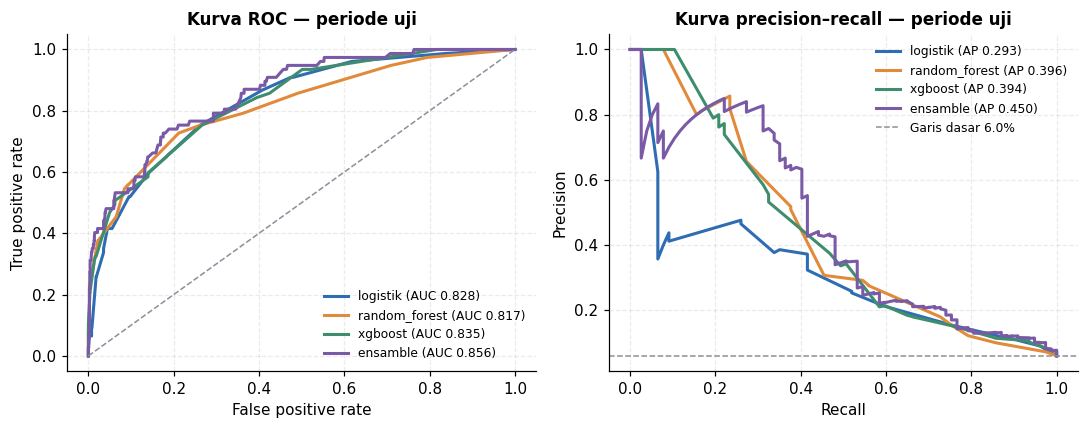

In [12]:
warna_model = {
    "logistik": PALET["biru"],
    "random_forest": PALET["oranye"],
    "xgboost": PALET["hijau"],
    "ensamble": PALET["ungu"],
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for nama, p in prob_uji.items():
    fpr, tpr, _ = roc_curve(y_uji, p)
    axes[0].plot(fpr, tpr, color=warna_model[nama], linewidth=2,
                 label=f"{nama} (AUC {roc_auc_score(y_uji, p):.3f})")
    presisi, recall, _ = precision_recall_curve(y_uji, p)
    axes[1].plot(recall, presisi, color=warna_model[nama], linewidth=2,
                 label=f"{nama} (AP {average_precision_score(y_uji, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=PALET["abu"], linestyle="--", linewidth=1)
axes[0].set_title("Kurva ROC — periode uji")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(frameon=False, fontsize=8)

garis_dasar = y_uji.mean()
axes[1].axhline(garis_dasar, color=PALET["abu"], linestyle="--", linewidth=1, label=f"Garis dasar {garis_dasar*100:.1f}%")
axes[1].set_title("Kurva precision–recall — periode uji")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_roc_pr.png")
plt.show()

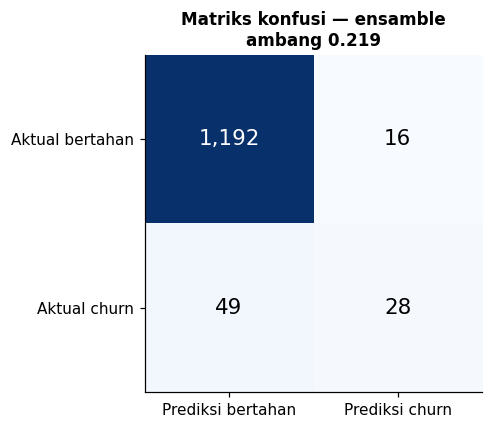

TP 28 | FP 16 | FN 49 | TN 1192


In [13]:
ambang_rekomendasi = ambang_model[rekomendasi]
prediksi_rekomendasi = (prob_uji[rekomendasi] >= ambang_rekomendasi).astype(int)
tp = int(((prediksi_rekomendasi == 1) & (y_uji == 1)).sum())
fp = int(((prediksi_rekomendasi == 1) & (y_uji == 0)).sum())
fn = int(((prediksi_rekomendasi == 0) & (y_uji == 1)).sum())
tn = int(((prediksi_rekomendasi == 0) & (y_uji == 0)).sum())

matriks = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(matriks, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matriks[i, j]:,}", ha="center", va="center",
                fontsize=14, color="white" if matriks[i, j] > matriks.max() / 2 else "black")
ax.set_xticks([0, 1], ["Prediksi bertahan", "Prediksi churn"])
ax.set_yticks([0, 1], ["Aktual bertahan", "Aktual churn"])
ax.set_title(f"Matriks konfusi — {rekomendasi}\nambang {ambang_rekomendasi:.3f}")
ax.grid(False)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_confusion_matrix.png")
plt.show()

print(f"TP {tp} | FP {fp} | FN {fn} | TN {tn}")

In [14]:
kurva_roc, kurva_pr = [], []
for nama, p in prob_uji.items():
    fpr, tpr, batas = roc_curve(y_uji, p)
    kurva_roc.append(pd.DataFrame({"model": nama, "fpr": fpr, "tpr": tpr}))
    presisi, recall, batas = precision_recall_curve(y_uji, p)
    kurva_pr.append(pd.DataFrame({"model": nama, "recall": recall, "precision": presisi}))
simpan(pd.concat(kurva_roc), CHURN_DIR / "churn_curve_roc.csv")
simpan(pd.concat(kurva_pr), CHURN_DIR / "churn_curve_pr.csv")

  tersimpan: data\processed\churn\churn_curve_roc.csv (399 baris)
  tersimpan: data\processed\churn\churn_curve_pr.csv (562 baris)


## 6. Faktor yang paling terkait dengan churn

Dua sudut pandang:
1. **Permutation importance** dari model terbaik: seberapa besar PR-AUC turun ketika satu fitur
   diacak.
2. **Perbandingan rata-rata** baris churn versus baris bertahan: angka yang bisa langsung
   dipakai di slide ("pelanggan churn punya keterlambatan X% lebih tinggi").

In [15]:
pipe_importance = Pipeline(
    [("pra", praproses()), ("model", model_dasar[tokoh_importance].__class__(**model_dasar[tokoh_importance].get_params()))]
)
pipe_importance.fit(X_latih, y_latih)

from sklearn.inspection import permutation_importance

kepentingan = permutation_importance(
    pipe_importance, X_uji, y_uji, scoring="average_precision",
    n_repeats=8, random_state=SEED, n_jobs=1,
)
tabel_kepentingan = (
    pd.DataFrame({"fitur": FITUR, "importance": kepentingan.importances_mean, "std": kepentingan.importances_std})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
tabel_kepentingan["model"] = tokoh_importance
simpan(tabel_kepentingan, CHURN_DIR / "churn_feature_importance.csv")
tabel_kepentingan.head(12).round(4)

  tersimpan: data\processed\churn\churn_feature_importance.csv (29 baris)


,fitur,importance,std,model
0,jenis_pelanggan,0.11,0.03,random_forest
1,recency_hari,0.05,0.02,random_forest
2,order_3,0.04,0.02,random_forest
3,late_rate_12,0.04,0.01,random_forest
4,unpaid_rate_12,0.03,0.01,random_forest
5,omzet_3,0.03,0.03,random_forest
6,delay_rata_12,0.02,0.01,random_forest
7,region,0.02,0.01,random_forest
8,tren_order,0.02,0.01,random_forest
9,diskon_rata_6,0.01,0.00,random_forest


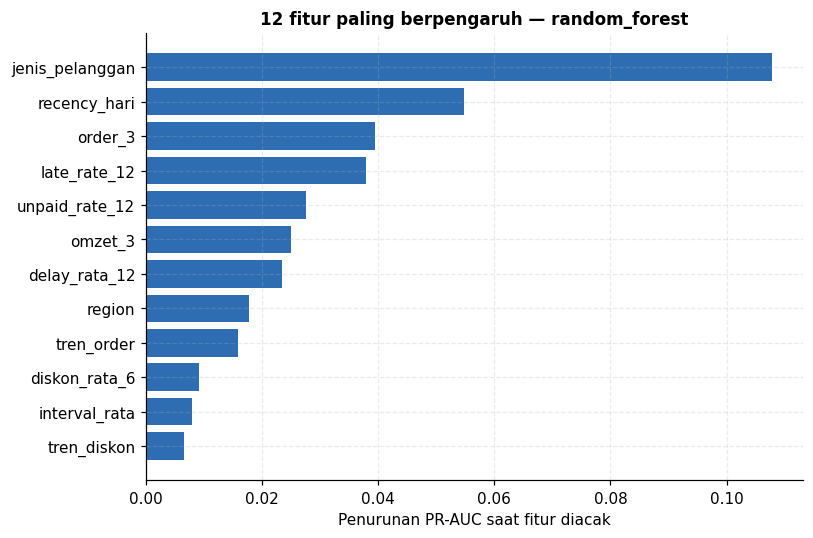

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5))
atas = tabel_kepentingan.head(12).iloc[::-1]
ax.barh(atas["fitur"], atas["importance"], color=PALET["biru"])
ax.set_title(f"12 fitur paling berpengaruh — {tokoh_importance}")
ax.set_xlabel("Penurunan PR-AUC saat fitur diacak")
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_feature_importance.png")
plt.show()

In [17]:
fitur_pemicu = [
    "recency_hari", "order_6", "omzet_6", "late_rate_12", "parah_rate_12",
    "retur_rate_12", "diskon_rata_6", "tren_diskon", "unpaid_rate_12", "tren_order",
]
pemicu = (
    panel.groupby("churn")[fitur_pemicu].mean().T
    .rename(columns={0: "bertahan", 1: "churn"})
    .reset_index().rename(columns={"index": "metrik"})
)
pemicu["selisih_relatif"] = (pemicu["churn"] - pemicu["bertahan"]) / pemicu["bertahan"].replace(0, np.nan)
simpan(pemicu, CHURN_DIR / "churn_drivers.csv")
pemicu.round(3)

  tersimpan: data\processed\churn\churn_drivers.csv (10 baris)


churn,metrik,bertahan,churn,selisih_relatif
0,recency_hari,22.41,84.06,2.75
1,order_6,6.92,3.35,-0.52
2,omzet_6,"35,195,627.25","15,835,863.03",-0.55
3,late_rate_12,0.13,0.32,1.39
4,parah_rate_12,0.08,0.18,1.27
5,retur_rate_12,0.03,0.05,0.47
6,diskon_rata_6,11.51,11.76,0.02
7,tren_diskon,-3.10,-8.16,1.63
8,unpaid_rate_12,0.25,0.21,-0.15
9,tren_order,0.11,-0.30,-3.73


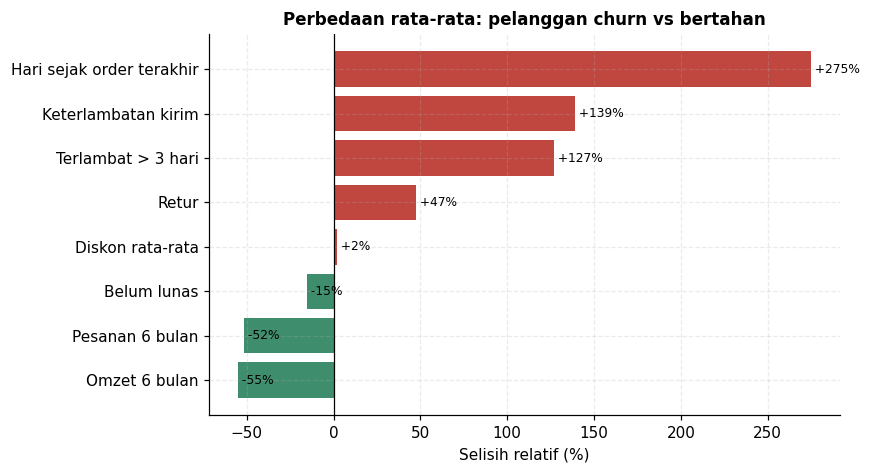

In [18]:
label_pemicu = {
    "late_rate_12": "Keterlambatan kirim",
    "parah_rate_12": "Terlambat > 3 hari",
    "retur_rate_12": "Retur",
    "unpaid_rate_12": "Belum lunas",
    "diskon_rata_6": "Diskon rata-rata",
    "recency_hari": "Hari sejak order terakhir",
    "order_6": "Pesanan 6 bulan",
    "omzet_6": "Omzet 6 bulan",
}
urut = pemicu[pemicu["metrik"].isin(label_pemicu)].copy()
urut["label"] = urut["metrik"].map(label_pemicu)
urut = urut.sort_values("selisih_relatif")
warna = [PALET["merah"] if v > 0 else PALET["hijau"] for v in urut["selisih_relatif"]]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(urut["label"], urut["selisih_relatif"] * 100, color=warna)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Perbedaan rata-rata: pelanggan churn vs bertahan")
ax.set_xlabel("Selisih relatif (%)")
for i, v in enumerate(urut["selisih_relatif"] * 100):
    ax.text(v, i, f" {v:+.0f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_pemicu.png")
plt.show()

## 7. Skor risiko per pelanggan (snapshot 31 Oktober 2026)

Model dilatih ulang memakai seluruh data panel yang berlabel (sampai April 2026), lalu dipakai
menilai 70 pelanggan yang masih aktif pada Oktober 2026. Pelanggan yang sudah tidak aktif
(30 orang) tidak dinilai probabilitasnya karena berada di luar wilayah data latih; mereka masuk
daftar **win-back**.

Pita risiko memakai kuantil di antara pelanggan aktif: 20% teratas = Tinggi, 30% berikutnya =
Sedang, sisanya Rendah. Probabilitasnya sudah dikalibrasi sehingga bisa dibaca sebagai perkiraan
peluang churn 180 hari, dengan catatan proporsi dasar hanya sekitar 3%.

In [19]:
m_snapshot = pd.Period("2026-10", freq="M")
fitur_snapshot = susun_fitur_historis(akt, [m_snapshot])
fitur_snapshot = fitur_snapshot.rename(columns={"churn": "churn_teoretis"}).drop(columns=["churn_teoretis"])

terakhir_semua = akt.groupby("id_pelanggan")["tanggal_transaksi"].max()
recency_semua = (snapshot - terakhir_semua).dt.days.rename("recency_hari")


def jendela_pada(kolom: str, lebar: int, geser: int = 0, fungsi: str = "sum") -> pd.Series:
    tabel = ma if kolom in ma.columns else ma_semua
    seri = jendela(tabel, kolom, lebar, geser, fungsi)
    return seri.xs(m_snapshot, level="periode").rename(kolom)


fitur_snap = pd.concat(
    [
        jendela_pada("order", 3).rename("order_3"),
        jendela_pada("order", 6).rename("order_6"),
        jendela_pada("order", 12).rename("order_12"),
        jendela_pada("order", 3, geser=3).rename("order_3_sebelum"),
        jendela_pada("omzet", 3).rename("omzet_3"),
        jendela_pada("omzet", 6).rename("omzet_6"),
        jendela_pada("omzet", 12).rename("omzet_12"),
        jendela_pada("items", 6).rename("items_6"),
        jendela_pada("n_baris", 3).rename("n_baris_3"),
        jendela_pada("n_baris", 6).rename("n_baris_6"),
        jendela_pada("n_baris", 12).rename("n_baris_12"),
        jendela_pada("n_terlambat", 12).rename("n_terlambat_12"),
        jendela_pada("n_parah", 12).rename("n_parah_12"),
        jendela_pada("n_retur", 12).rename("n_retur_12"),
        jendela_pada("n_belum_lunas", 12).rename("n_belum_lunas_12"),
        jendela_pada("diskon_sum", 3).rename("diskon_sum_3"),
        jendela_pada("diskon_sum", 3, geser=3).rename("diskon_sum_3_sebelum"),
        jendela_pada("diskon_sum", 6).rename("diskon_sum_6"),
        jendela_pada("delay_sum", 12).rename("delay_sum_12"),
        jendela_pada("n_semua", 12).rename("n_semua_12"),
        jendela_pada("n_batal", 12).rename("n_batal_12"),
    ],
    axis=1,
)

skor = pelanggan.set_index("id_pelanggan")[
    ["nama_pelanggan", "jenis_pelanggan", "segmen", "provinsi", "kota", "region",
     "kanal_akuisisi", "termin_pembayaran", "limit_kredit", "tenure_hari"]
].join(recency_semua).join(fitur_snap, how="left").join(
    fitur_snapshot.set_index("id_pelanggan")[
        ["tenure_bulan", "interval_rata", "interval_std", "produk_unik_12", "kategori_unik_12"]
    ],
    how="left",
)
skor["aov_12"] = skor["omzet_12"] / skor["order_12"].replace(0, np.nan)
skor["tren_order"] = (skor["order_3"] - skor["order_3_sebelum"]) / (skor["order_3_sebelum"] + 1)
skor["late_rate_12"] = skor["n_terlambat_12"] / skor["n_baris_12"].replace(0, np.nan)
skor["parah_rate_12"] = skor["n_parah_12"] / skor["n_baris_12"].replace(0, np.nan)
skor["delay_rata_12"] = skor["delay_sum_12"] / skor["n_baris_12"].replace(0, np.nan)
skor["retur_rate_12"] = skor["n_retur_12"] / skor["n_baris_12"].replace(0, np.nan)
skor["unpaid_rate_12"] = skor["n_belum_lunas_12"] / skor["n_baris_12"].replace(0, np.nan)
skor["batal_rate_12"] = skor["n_batal_12"] / skor["n_semua_12"].replace(0, np.nan)
skor["diskon_rata_6"] = skor["diskon_sum_6"] / skor["n_baris_6"].replace(0, np.nan)
skor["diskon_rata_3"] = skor["diskon_sum_3"] / skor["n_baris_3"].replace(0, np.nan)
skor["diskon_rata_3_sebelum"] = skor["diskon_sum_3_sebelum"] / skor["n_baris_3"].replace(0, np.nan)
skor["tren_diskon"] = skor["diskon_rata_3"] - skor["diskon_rata_3_sebelum"]
skor["tenure_bulan"] = skor["tenure_bulan"].fillna(skor["tenure_hari"] / 30.44)
skor = skor.replace([np.inf, -np.inf], np.nan)

aktif_mask = skor["recency_hari"] <= 180
X_skor = skor[FITUR].copy()

pipe_final = {
    nama: Pipeline([("pra", praproses()), ("model", model_dasar[nama].__class__(**model_dasar[nama].get_params()))])
    for nama in model_dasar
}
for nama, pipe in pipe_final.items():
    pipe.fit(panel[FITUR], panel["churn"])

kolom_prob = {"logistik": "prob_logistik", "random_forest": "prob_random_forest", "xgboost": "prob_xgboost"}
for nama, kolom in kolom_prob.items():
    skor[kolom] = np.nan
    if aktif_mask.any():
        mentah = pipe_final[nama].predict_proba(X_skor[aktif_mask])[:, 1]
        skor.loc[aktif_mask, kolom] = kalibrator[nama].predict(mentah)

skor["prob_ensamble"] = skor[list(kolom_prob.values())].mean(axis=1)
skor["status"] = np.where(aktif_mask, "Aktif", "Win-back")
aktif_prob = skor.loc[aktif_mask, "prob_ensamble"]
ambang_tinggi = aktif_prob.quantile(0.8)
ambang_sedang = aktif_prob.quantile(0.5)
band_aktif = pd.Series("Rendah", index=aktif_prob.index)
band_aktif[aktif_prob >= ambang_sedang] = "Sedang"
band_aktif[aktif_prob >= ambang_tinggi] = "Tinggi"
skor["band_kuantil"] = band_aktif.reindex(skor.index).fillna("Win-back")
skor.loc[~aktif_mask, "band_kuantil"] = "Win-back"
skor["peringkat_risiko"] = np.nan
skor.loc[aktif_mask, "peringkat_risiko"] = aktif_prob.rank(ascending=False, method="first")

kolom_skor = [
    "nama_pelanggan", "jenis_pelanggan", "segmen", "provinsi", "kota", "region",
    "kanal_akuisisi", "termin_pembayaran", "status", "recency_hari",
    "order_6", "order_12", "omzet_6", "omzet_12", "aov_12",
    "late_rate_12", "parah_rate_12", "retur_rate_12", "diskon_rata_6", "unpaid_rate_12",
    "tenure_bulan", "limit_kredit",
    "prob_logistik", "prob_random_forest", "prob_xgboost", "prob_ensamble",
    "band_kuantil", "peringkat_risiko",
]
skor_keluar = skor[kolom_skor].reset_index().sort_values(
    ["status", "prob_ensamble"], ascending=[True, False]
)
simpan(skor_keluar, CHURN_DIR / "churn_scores.csv")
print(f"pelanggan aktif dinilai: {int(aktif_mask.sum())}")
print(f"pita Tinggi: {int((skor['band_kuantil']=='Tinggi').sum())} | Sedang: {int((skor['band_kuantil']=='Sedang').sum())}")
skor_keluar.head(10).round(3)

  tersimpan: data\processed\churn\churn_scores.csv (100 baris)
pelanggan aktif dinilai: 70
pita Tinggi: 14 | Sedang: 21


,id_pelanggan,nama_pelanggan,jenis_pelanggan,segmen,provinsi,kota,region,kanal_akuisisi,termin_pembayaran,status,recency_hari,order_6,order_12,omzet_6,omzet_12,aov_12,late_rate_12,parah_rate_12,retur_rate_12,diskon_rata_6,unpaid_rate_12,tenure_bulan,limit_kredit,prob_logistik,prob_random_forest,prob_xgboost,prob_ensamble,band_kuantil,peringkat_risiko
35,CUST-0036,PT Nusa Persada,Korporat,Silver,Kalimantan Timur,Balikpapan,Kalimantan,Kunjungan Sales,COD,Aktif,112,2.00,8.00,"6,330,347.10","27,802,721.00","3,475,340.12",0.56,0.33,0.00,11.27,0.00,85.51,"155,000,000.00",0.29,0.79,0.12,0.40,Tinggi,1.00
9,CUST-0010,PT Surya Properti,Toko Bangunan,Silver,DKI Jakarta,Jakarta Timur,Jawa,Pameran,COD,Aktif,149,2.00,6.00,"12,996,698.70","24,492,003.50","4,082,000.58",0.25,0.25,0.25,6.50,0.12,87.39,"80,000,000.00",0.30,0.36,0.07,0.24,Tinggi,2.00
68,CUST-0069,Toko Prima Jaya,Toko Bangunan,Bronze,Sumatera Utara,Medan,Sumatera,Referral,60 Hari,Aktif,166,1.00,6.00,"9,973,087.30","40,406,489.30","6,734,414.88",0.60,0.60,0.00,6.67,0.40,81.90,"190,000,000.00",0.12,0.36,0.12,0.20,Tinggi,3.00
85,CUST-0086,CV Cipta Beton,Toko Bangunan,Silver,Jawa Timur,Malang,Jawa,Telemarketing,30 Hari,Aktif,94,4.00,10.00,"21,491,446.50","56,043,718.70","5,604,371.87",0.29,0.12,0.18,6.71,0.18,90.54,"65,000,000.00",0.15,0.36,0.07,0.20,Tinggi,4.00
75,CUST-0076,CV Bangun Abadi,Toko Bangunan,Silver,DKI Jakarta,Jakarta Barat,Jawa,Kunjungan Sales,COD,Aktif,41,2.00,6.00,"9,411,835.60","26,208,256.00","4,368,042.67",0.25,0.25,0.00,8.83,0.25,28.98,"165,000,000.00",0.05,0.18,0.12,0.12,Tinggi,5.00
34,CUST-0035,Toko Global Makmur,Toko Bangunan,Silver,Jawa Barat,Bekasi,Jawa,Kunjungan Sales,30 Hari,Aktif,36,2.00,4.00,"4,083,086.80","17,050,655.50","4,262,663.88",0.33,0.33,0.00,10.95,0.17,87.52,"195,000,000.00",0.06,0.18,0.07,0.10,Tinggi,6.00
87,CUST-0088,CV Cipta Abadi,Korporat,Silver,DKI Jakarta,Jakarta Selatan,Jawa,Pameran,30 Hari,Aktif,55,2.00,2.00,"10,720,970.40","10,720,970.40","5,360,485.20",0.00,0.00,0.50,9.10,0.00,26.35,"385,000,000.00",0.06,0.06,0.12,0.08,Tinggi,7.00
2,CUST-0003,Toko Mulia Niaga,Toko Bangunan,Bronze,DKI Jakarta,Jakarta Timur,Jawa,Kunjungan Sales,COD,Aktif,169,1.00,3.00,"5,095,948.20","14,520,536.70","4,840,178.90",0.00,0.00,0.00,9.35,1.00,78.48,"115,000,000.00",0.06,0.10,0.04,0.07,Tinggi,8.00
71,CUST-0072,CV Bumi Sentosa,Toko Bangunan,Bronze,Sumatera Utara,Medan,Sumatera,Referral,30 Hari,Aktif,0,3.00,5.00,"9,086,434.50","17,619,350.10","3,523,870.02",0.20,0.20,0.20,10.63,0.40,59.17,"65,000,000.00",0.06,0.06,0.07,0.06,Tinggi,9.00
78,CUST-0079,Toko Karya Perkasa,Toko Bangunan,Silver,Jawa Tengah,Surakarta,Jawa,Telemarketing,COD,Aktif,15,10.00,17.00,"74,768,622.10","122,032,212.60","7,178,365.45",0.26,0.20,0.17,7.28,0.26,44.68,"135,000,000.00",0.06,0.06,0.07,0.06,Tinggi,10.00


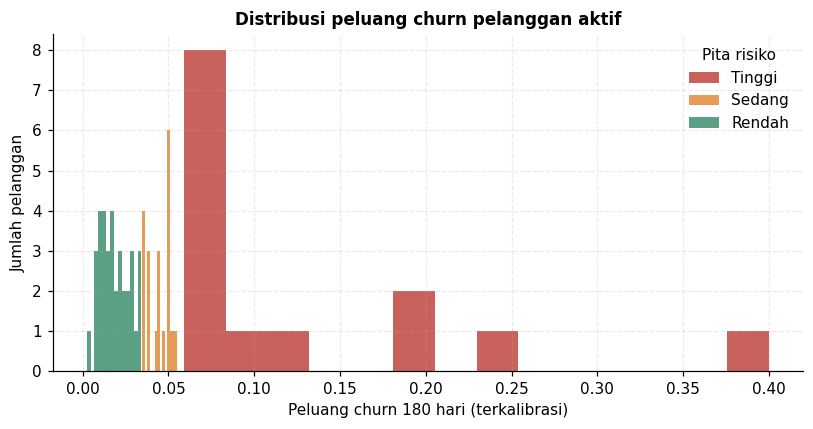

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4))
warna_band = {"Tinggi": PALET["merah"], "Sedang": PALET["oranye"], "Rendah": PALET["hijau"]}
for band, warna in warna_band.items():
    nilai = aktif_prob[skor.loc[aktif_mask, "band_kuantil"] == band]
    ax.hist(nilai, bins=14, color=warna, alpha=0.85, label=band)
ax.set_title("Distribusi peluang churn pelanggan aktif")
ax.set_xlabel("Peluang churn 180 hari (terkalibrasi)")
ax.set_ylabel("Jumlah pelanggan")
ax.legend(frameon=False, title="Pita risiko")
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_distribusi_risiko.png")
plt.show()

## 8. Risiko per segmen

Tabel ini menggabungkan dua sudut pandang untuk Halaman 2 dashboard:
churn historis (fakta) dan rata-rata risiko prediksi pelanggan yang masih aktif (perkiraan).

In [21]:
historis = pelanggan[["id_pelanggan", "dinilai", "churn", "aktif"]].copy()
gabung = skor.join(historis.set_index("id_pelanggan")[["dinilai", "churn", "aktif"]])

baris_segmen = []
for dimensi in ["jenis_pelanggan", "segmen", "region", "provinsi", "kanal_akuisisi", "termin_pembayaran"]:
    for kategori, g in gabung.groupby(dimensi):
        dinilai_g = g[g["dinilai"] == True]
        aktif_g = g[g["aktif"] == True]
        baris_segmen.append(
            {
                "dimensi": dimensi,
                "kategori": kategori,
                "n_pelanggan": len(g),
                "n_dinilai": len(dinilai_g),
                "n_churn_historis": int(dinilai_g["churn"].sum()),
                "churn_rate_historis": dinilai_g["churn"].mean() if len(dinilai_g) else np.nan,
                "n_aktif": len(aktif_g),
                "n_risiko_tinggi": int((aktif_g["band_kuantil"] == "Tinggi").sum()),
                "rata2_prob": aktif_g["prob_ensamble"].mean() if len(aktif_g) else np.nan,
                "omzet_12_bulan": aktif_g["omzet_12"].sum(),
            }
        )

tabel_segmen = pd.DataFrame(baris_segmen)
simpan(tabel_segmen, CHURN_DIR / "churn_segment_risk.csv")
tabel_segmen[tabel_segmen["dimensi"] == "jenis_pelanggan"].round(3)

  tersimpan: data\processed\churn\churn_segment_risk.csv (35 baris)


,dimensi,kategori,n_pelanggan,n_dinilai,n_churn_historis,churn_rate_historis,n_aktif,n_risiko_tinggi,rata2_prob,omzet_12_bulan
0,jenis_pelanggan,Developer,8,8,0,0.00,8,0,0.02,"750,740,246.80"
1,jenis_pelanggan,Kontraktor,25,25,1,0.04,24,1,0.03,"2,063,343,112.40"
2,jenis_pelanggan,Korporat,12,12,2,0.17,10,2,0.07,"852,108,013.35"
3,jenis_pelanggan,Toko Bangunan,55,55,27,0.49,28,11,0.07,"1,384,947,055.80"


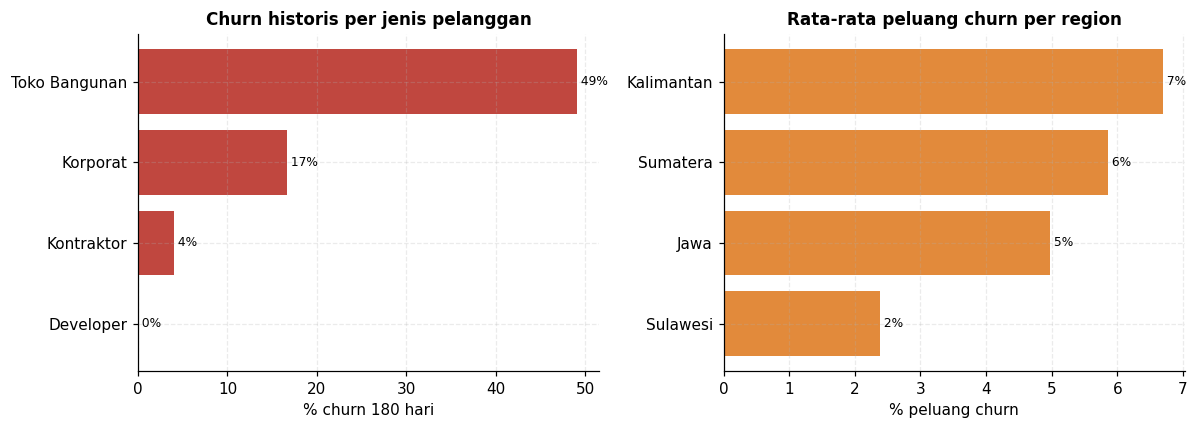

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bagian_jenis = tabel_segmen[tabel_segmen["dimensi"] == "jenis_pelanggan"].sort_values("churn_rate_historis")
axes[0].barh(bagian_jenis["kategori"], bagian_jenis["churn_rate_historis"] * 100, color=PALET["merah"])
axes[0].set_title("Churn historis per jenis pelanggan")
axes[0].set_xlabel("% churn 180 hari")
for i, v in enumerate(bagian_jenis["churn_rate_historis"] * 100):
    axes[0].text(v, i, f" {v:.0f}%", va="center", fontsize=8)

bagian_region = tabel_segmen[tabel_segmen["dimensi"] == "region"].sort_values("rata2_prob")
axes[1].barh(bagian_region["kategori"], bagian_region["rata2_prob"] * 100, color=PALET["oranye"])
axes[1].set_title("Rata-rata peluang churn per region")
axes[1].set_xlabel("% peluang churn")
for i, v in enumerate(bagian_region["rata2_prob"] * 100):
    axes[1].text(v, i, f" {v:.0f}%", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(GAMBAR_DIR / "churn_segmen_risiko.png")
plt.show()

## 9. Ringkasan untuk dashboard

Yang diekspor ke `data/processed/churn/`:

| Berkas | Isi | Dipakai untuk |
|---|---|---|
| `churn_snapshot_kpi.csv` | 30/100 churn, omzet 12 bulan | KPI Halaman 1 |
| `churn_rate_monthly.csv` | prevalensi churn per bulan | tren Halaman 1 |
| `churn_scores.csv` | 100 pelanggan + 3 model + ensamble + pita risiko | tabel/scatter Halaman 2 |
| `churn_segment_risk.csv` | churn historis & risiko prediksi per segmen | perbandingan segmen |
| `churn_drivers.csv` | rata-rata pemicu churn vs bertahan | faktor penyebab |
| `churn_feature_importance.csv` | permutation importance | grafik fitur |
| `churn_model_metrics.csv` | AUC, PR-AUC, recall@20%, F1, Brier | evaluasi model |
| `churn_curve_roc.csv`, `churn_curve_pr.csv` | titik kurva | grafik evaluasi |

**Batas tafsir:** dataset sintetis, 100 pelanggan, 33 kejadian churn. Metrik bisa berubah cukup
besar bila seed data diganti. Probabilitas sudah dikalibrasi, tetapi tetap perkiraan relatif:
gunakan pita kuantil untuk prioritas kampanye, bukan sebagai angka pasti.

In [23]:
ringkasan = {
    "tanggal_snapshot": str(snapshot.date()),
    "panel_baris": int(len(panel)),
    "panel_positif": int(panel["churn"].sum()),
    "pelanggan_aktif_dinilai": int(aktif_mask.sum()),
    "model_rekomendasi": rekomendasi,
    "ambang_rekomendasi": float(ambang_rekomendasi),
    "churn_rate_historis": float(dinilai["churn"].mean()),
    "pita_tinggi": int((skor["band_kuantil"] == "Tinggi").sum()),
    "pelanggan_winback": int((~aktif_mask).sum()),
}
ringkasan

{'tanggal_snapshot': '2026-10-31',
 'panel_baris': 5669,
 'panel_positif': 184,
 'pelanggan_aktif_dinilai': 70,
 'model_rekomendasi': 'ensamble',
 'ambang_rekomendasi': 0.21929379262712598,
 'churn_rate_historis': 0.3,
 'pita_tinggi': 14,
 'pelanggan_winback': 30}

## 10. Temuan

- **Churn deskriptif 30%** (30 dari 100 pelanggan dinilai) per 31 Oktober 2026; 70 masih aktif.
  Konsentrasi terbesar ada di **Toko Bangunan 49%** (27 dari 55), dibanding Kontraktor 4%,
  Korporat 17%, dan Developer 0%.
- **Model ensambel** dipilih: CV ROC-AUC 0,878 dan PR-AUC 0,356; pada uji waktu 2025–April 2026
  PR-AUC 0,450 dan **recall@20% 0,688**, artinya 20% pelanggan berisiko tertinggi menangkap
  sekitar 69% churner di periode uji. Baseline proporsi positif hanya 6% pada periode uji.
- **Pemicu utama** pada baris mendekati churn: keterlambatan kirim +139%, terlambat >3 hari
  +127%, retur +47%, serta penurunan pesanan 6 bulan −52% dan omzet 6 bulan −55%. Perubahan
  diskon juga lebih tajam turun (−8,2 pp vs −3,1 pp), sesuai pola diskon ditarik sebelum churn.
- **Skor snapshot:** 14 pelanggan pita Tinggi, 21 Sedang, 35 Rendah, dan 30 pelanggan masuk
  daftar win-back. Sebelas dari 14 pelanggan pita Tinggi adalah Toko Bangunan.
- **Implikasi:** prioritas kampanye retensi adalah Toko Bangunan di Jawa Barat/Sumatera dengan
  riwayat keterlambatan atau retur, bukan diskon merata ke semua segmen.

**Batas tafsir:** data sintetis dengan 33 kejadian churn; peluang terkalibrasi memakai proporsi
dasar ±3% per pelanggan-bulan, jadi gunakan pita kuantil untuk prioritas, bukan angka absolut.
